# 01 – Load and explore BCI Competition IV 2a
Goal: load one subject, check the data, and compare raw vs. band-pass filtered EEG over motor cortex (C3, Cz, C4).

In [6]:
import mne
import matplotlib.pyplot as plt

In [9]:
raw = mne.io.read_raw_gdf("../data/BCICIV_2a_gdf/A01T.gdf", preload=True)
raw.set_channel_types({"EOG-left": "eog", "EOG-central": "eog", "EOG-right": "eog"})
print(raw.info)

Extracting EDF parameters from /Users/haasiniyelugoti/Downloads/projs/eeg-motor-imagery-decoder/data/BCICIV_2a_gdf/A01T.gdf...
GDF file detected
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 672527  =      0.000 ...  2690.108 secs...


/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/contextlib.py:124: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


<Info | 8 non-empty values
 bads: []
 ch_names: EEG-Fz, EEG-0, EEG-1, EEG-2, EEG-3, EEG-4, EEG-5, EEG-C3, EEG-6, ...
 chs: 22 EEG, 3 EOG
 custom_ref_applied: False
 highpass: 0.5 Hz
 lowpass: 100.0 Hz
 meas_date: 2005-01-17 12:00:00 UTC
 nchan: 25
 projs: []
 sfreq: 250.0 Hz
 subject_info: 4 items (dict)
>


In [10]:
eeg_channels = mne.pick_types(raw.info, eeg=True)
print("Number of EEG channels:", len(eeg_channels))
print("Sampling rate (Hz):", raw.info["sfreq"])
print("Channel names:", raw.ch_names)

Number of EEG channels: 22
Sampling rate (Hz): 250.0
Channel names: ['EEG-Fz', 'EEG-0', 'EEG-1', 'EEG-2', 'EEG-3', 'EEG-4', 'EEG-5', 'EEG-C3', 'EEG-6', 'EEG-Cz', 'EEG-7', 'EEG-C4', 'EEG-8', 'EEG-9', 'EEG-10', 'EEG-11', 'EEG-12', 'EEG-13', 'EEG-14', 'EEG-Pz', 'EEG-15', 'EEG-16', 'EOG-left', 'EOG-central', 'EOG-right']


In [11]:
events, event_id = mne.events_from_annotations(raw)
classes = {"left_hand": "769", "right_hand": "770", "feet": "771", "tongue": "772"}
for name, code in classes.items():
    n = (events[:, 2] == event_id[code]).sum()
    print(f"{name}: {n} trials")

Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
left_hand: 72 trials
right_hand: 72 trials
feet: 72 trials
tongue: 72 trials


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 8 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 8.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 7.00 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 413 samples (1.652 s)



[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.2s
[Parallel(n_jobs=1)]: Done  22 out of  22 | elapsed:    0.2s finished


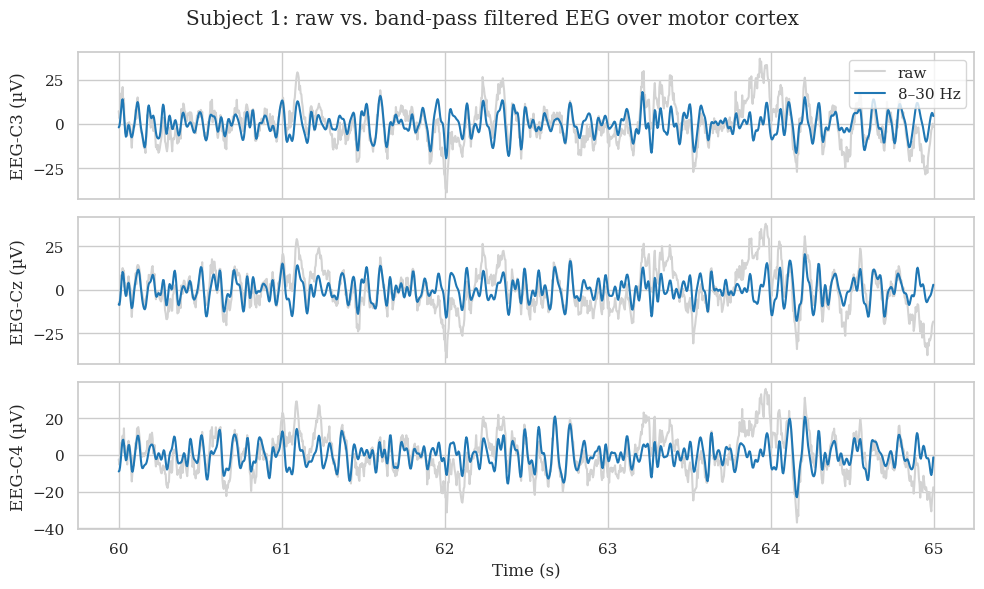

In [13]:
picks = ["EEG-C3", "EEG-Cz", "EEG-C4"]
raw_filt = raw.copy().filter(l_freq=8, h_freq=30)
sfreq = raw.info["sfreq"]
start = int(60 * sfreq)            # start 60 seconds in
stop = start + int(5 * sfreq)      # show 5 seconds

raw_data, times = raw.copy().pick(picks).get_data(start=start, stop=stop, return_times=True)
filt_data = raw_filt.copy().pick(picks).get_data(start=start, stop=stop)

fig, axes = plt.subplots(len(picks), 1, sharex=True, figsize=(10, 6))
for ax, ch, r, f in zip(axes, picks, raw_data, filt_data):
    ax.plot(times, r * 1e6, color="lightgray", label="raw")
    ax.plot(times, f * 1e6, color="tab:blue", label="8–30 Hz")
    ax.set_ylabel(f"{ch} (µV)")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Subject 1: raw vs. band-pass filtered EEG over motor cortex")
plt.tight_layout()
fig.savefig("../figures/raw_vs_filtered.png", dpi=150)
plt.show()

In [ ]:
# Notes:


# Num of EEG channels: 22
# Sampling rate (Hz): 250
# Number of trials: 120
# left hand: 30 trials
# right hand: 30 trials
# feet: 30 trials
# tongue: 30 trials 